# Thực nghiệm K-Means — Nguyễn Văn Thành

Dùng đúng tập PCA **3.000 × 104** do Ly bàn giao. Mục tiêu: khảo sát K=2…10, chọn K bằng Silhouette, phân tích Elbow và đánh giá bên ngoài sau khi chốt K.

Không lấy mẫu lại, không chuẩn hóa lại và không fit PCA lại. Chỉ PC1…PC104 được đưa vào mô hình; Activity, ActivityName, Subject và Original_Index được tách khỏi ma trận đầu vào.

## 1. Nguyên lý
K-Means lặp hai bước: gán điểm vào tâm gần nhất và cập nhật tâm bằng trung bình các điểm trong cụm. Hàm mục tiêu là $J=\sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i-\mu_k\|_2^2$.

Inertia giảm khi K tăng nên không thể chỉ chọn K có Inertia nhỏ nhất. Notebook chọn Silhouette cao nhất (nếu bằng nhau, ưu tiên K nhỏ hơn); gợi ý Elbow là phép đo độ lệch lớn nhất so với dây nối hai đầu trên đường cong đã chuẩn hóa và chỉ có vai trò tham khảo.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'src/run_kmeans.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/run_kmeans.py').exists(), 'Mở notebook từ thư mục gốc hoặc notebooks của repo.'
sys.path.insert(0, str(ROOT / 'src'))
from run_kmeans import load_inputs, run_experiment
OUT = ROOT / 'results/kmeans'


## 2. Kiểm tra bàn giao
Kiểm tra số mẫu, các cột PCA, giá trị không hữu hạn, Original_Index, thứ tự dòng và nhãn hoạt động so với dữ liệu UCI HAR gốc. Kiểm tra nhãn chỉ nhằm bảo đảm ghép dòng đúng, không ảnh hưởng đến huấn luyện hoặc chọn K.


In [2]:
data, indices, X, config, *_ = load_inputs(ROOT)
print('Đầu vào mô hình:', X.shape)
print('Chuẩn hóa:', config['scaler'])
print('Số PC:', config['pca_components'])
print('Phương sai tích lũy (%):', config['pca_cumulative_variance'])
print('Cấu hình lấy mẫu random_state:', config['random_state'])
print('Các cột loại khỏi mô hình: Activity, ActivityName, Subject, Original_Index')


Đầu vào mô hình: (3000, 104)
Chuẩn hóa: StandardScaler
Số PC: 104
Phương sai tích lũy (%): 95.05
Cấu hình lấy mẫu random_state: 42
Các cột loại khỏi mô hình: Activity, ActivityName, Subject, Original_Index


## 3. Chạy K=2…10
Cấu hình cố định: k-means++, n_init=20, max_iter=300, tol=0.0001, random_state=42, Lloyd, một luồng tính toán. Silhouette tính trên toàn bộ 3.000 mẫu trong không gian 104 PC. Thời gian fit không gồm thời gian đọc file, tính chỉ số hoặc vẽ hình; không dùng để suy ra tốc độ trên máy khác.


In [3]:
results, predictions, manifest = run_experiment(ROOT)
display(results.round(6))
print('K được chọn:', manifest['selected_k'])
print('Gợi ý Elbow hình học:', manifest['elbow_geometric_candidate'])


K=2: Silhouette=0.415237, inertia=856617.49
K=3: Silhouette=0.335964, inertia=752380.84
K=4: Silhouette=0.170098, inertia=710773.77
K=5: Silhouette=0.135114, inertia=676453.89
K=6: Silhouette=0.133631, inertia=653573.61
K=7: Silhouette=0.094515, inertia=634858.35
K=8: Silhouette=0.093078, inertia=619874.04
K=9: Silhouette=0.082977, inertia=605321.63
K=10: Silhouette=0.085344, inertia=593029.20
Chọn K=2; gợi ý Elbow=5. K=6 chỉ là thực nghiệm bổ sung.
K được chọn: 2
Gợi ý Elbow hình học: 5


,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Fit_seconds,Iterations,Min_cluster_size,Max_cluster_size,ARI,NMI
0,2,856617.492676,0.415237,1.011435,2565.820069,0.038585,5,1362,1638,0.330108,0.547843
1,3,752380.842623,0.335964,1.659955,1667.766058,0.060633,7,446,1632,0.330949,0.519221
2,4,710773.773113,0.170098,2.167783,1234.995801,0.079628,15,446,1025,0.296456,0.470321
3,5,676453.894377,0.135114,2.388894,1010.902946,0.151742,11,163,1026,0.283000,0.456487
4,6,653573.611215,0.133631,2.161166,857.717375,0.191484,12,59,791,0.416495,0.562532
5,7,634858.351865,0.094515,2.444124,750.294875,0.283253,26,46,766,0.419044,0.548214
6,8,619874.043968,0.093078,2.376388,668.768114,0.258286,19,41,620,0.407992,0.544600
7,9,605321.632326,0.082977,2.411956,608.028071,0.254291,24,21,619,0.440722,0.563954
8,10,593029.200439,0.085344,2.384746,558.374285,0.314107,25,20,619,0.436718,0.554973


## 4. Elbow và Silhouette
Nếu Elbow và Silhouette không đồng thuận, báo cáo cả hai. Không ép K bằng sáu hoạt động đã biết và không chọn K bằng ARI/NMI.


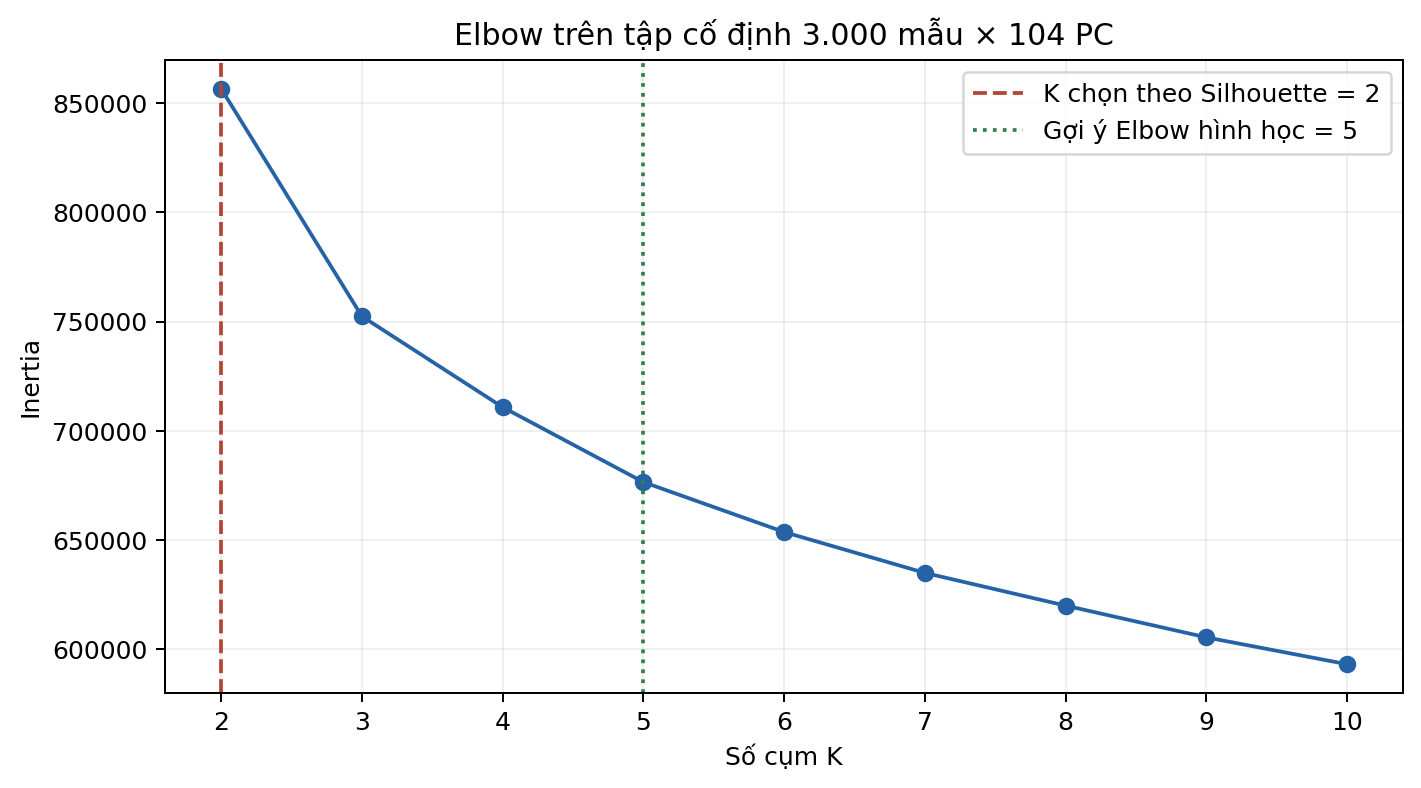

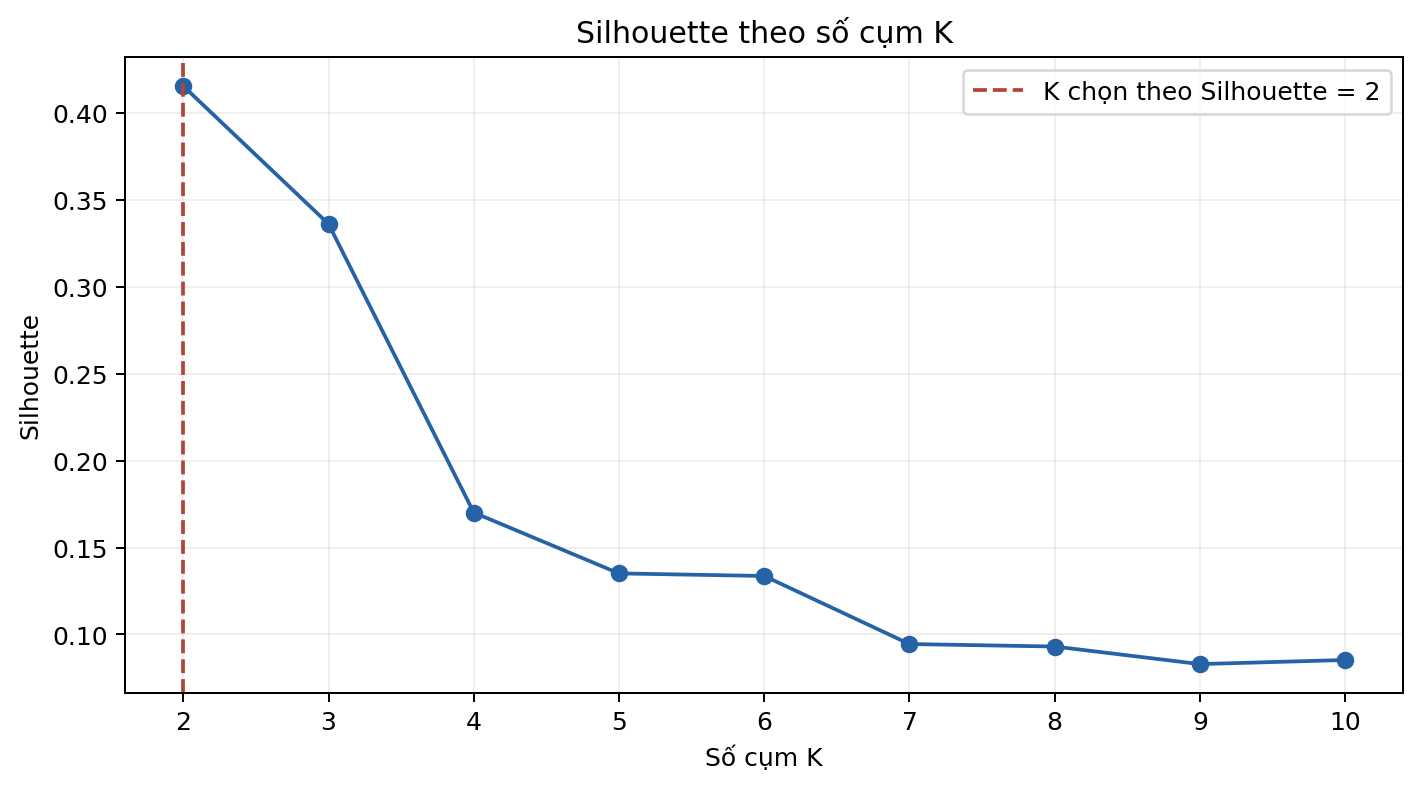

In [4]:
display(Image(filename=str(OUT / 'fig_5_1_elbow.png')))
display(Image(filename=str(OUT / 'fig_5_2_silhouette.png')))


## 5. Mô hình được chọn
Silhouette và Calinski–Harabasz cao hơn, Davies–Bouldin thấp hơn thường là dấu hiệu tốt trên cùng đầu vào. ARI/NMI đo mức tương đồng với sáu nhãn tham chiếu sau phân cụm, không phải độ chính xác phân loại. Mã cụm chỉ là định danh, không tương ứng trực tiếp mã hoạt động.


,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Fit_seconds,Iterations,Min_cluster_size,Max_cluster_size,ARI,NMI
0,2,856617.492676,0.415237,1.011435,2565.820069,0.038585,5,1362,1638,0.330108,0.547843


,Cluster,Samples,Percent
0,0,1362,45.4
1,1,1638,54.6


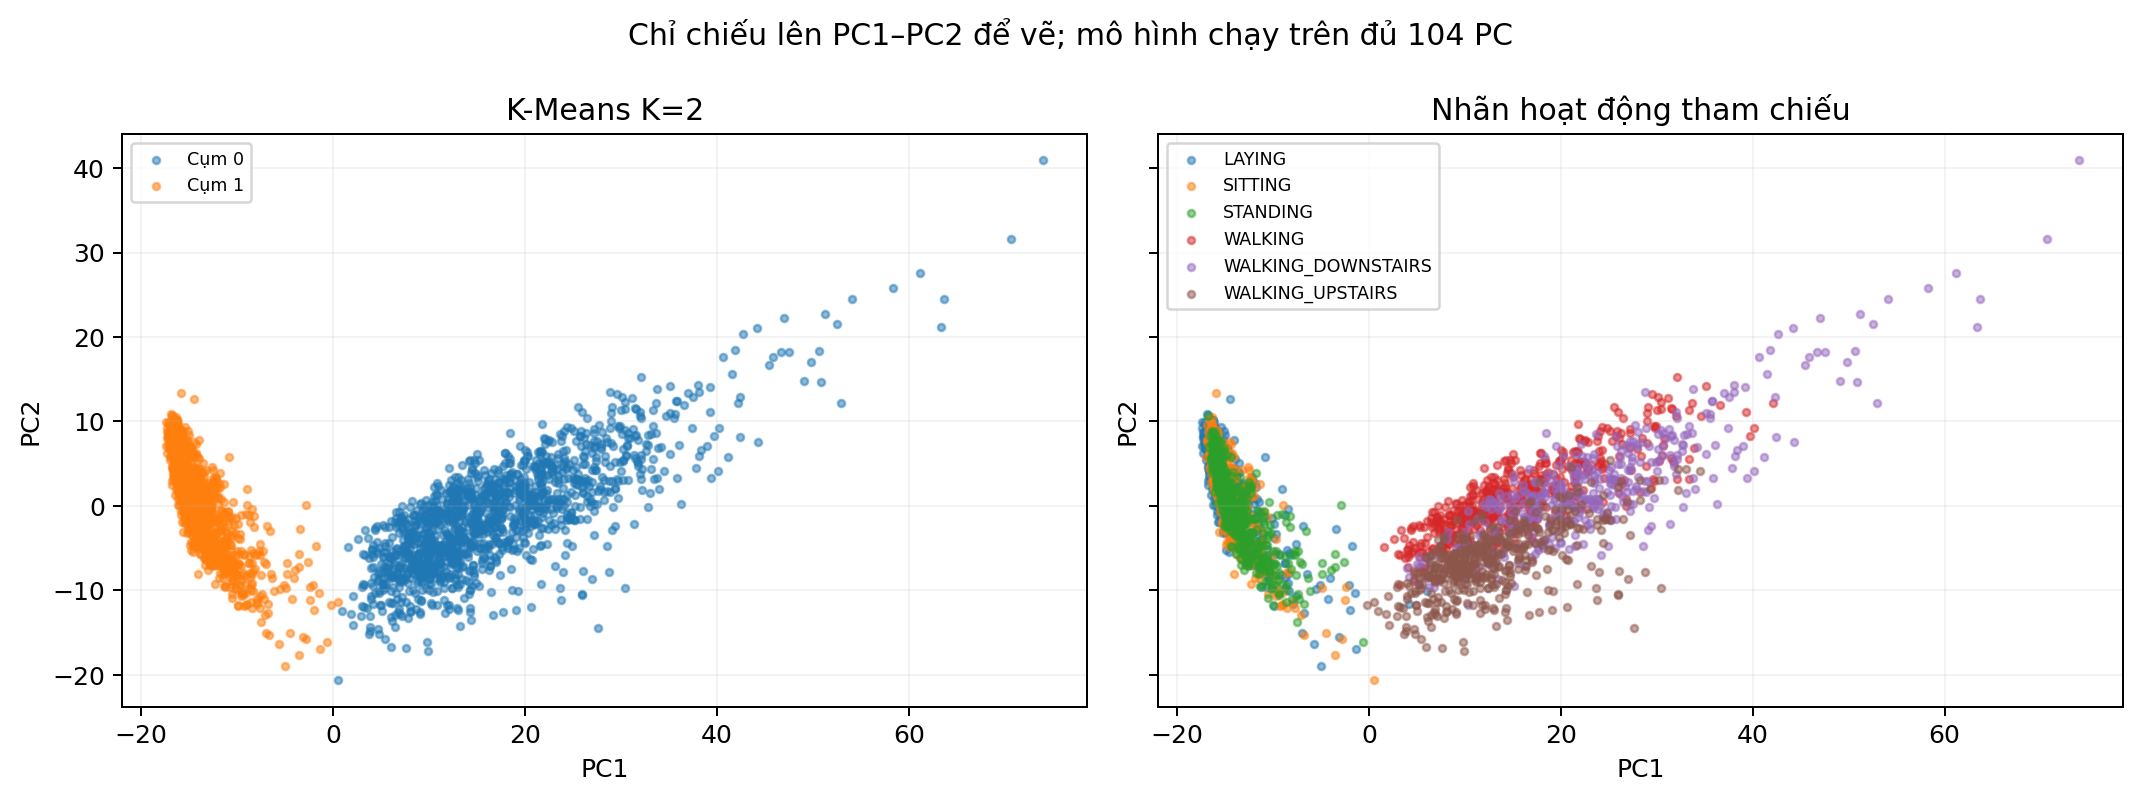

In [5]:
k = manifest['selected_k']
display(results.loc[results['K'] == k].round(6))
display(pd.read_csv(OUT / 'cluster_sizes.csv').round(3))
display(Image(filename=str(OUT / 'fig_5_3_clusters_pca2d.png')))


## 6. Đối chiếu cụm với hoạt động
Hình chiếu PC1–PC2 chỉ phục vụ trực quan hóa. Đánh giá định lượng vẫn dùng đủ 104 PC. Bảng chéo giúp nhận biết cấu trúc hoạt động động/tĩnh và các hoạt động bị gom chung. K=6 được giữ làm thực nghiệm bổ sung, không thay thế K đã chọn.


Thực nghiệm bổ sung K=6:
Tỷ lệ mẫu có Silhouette âm (%): 0.26666666666666666


,Cluster,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
0,0,2,1,0,502,409,448
1,1,564,517,555,0,0,2


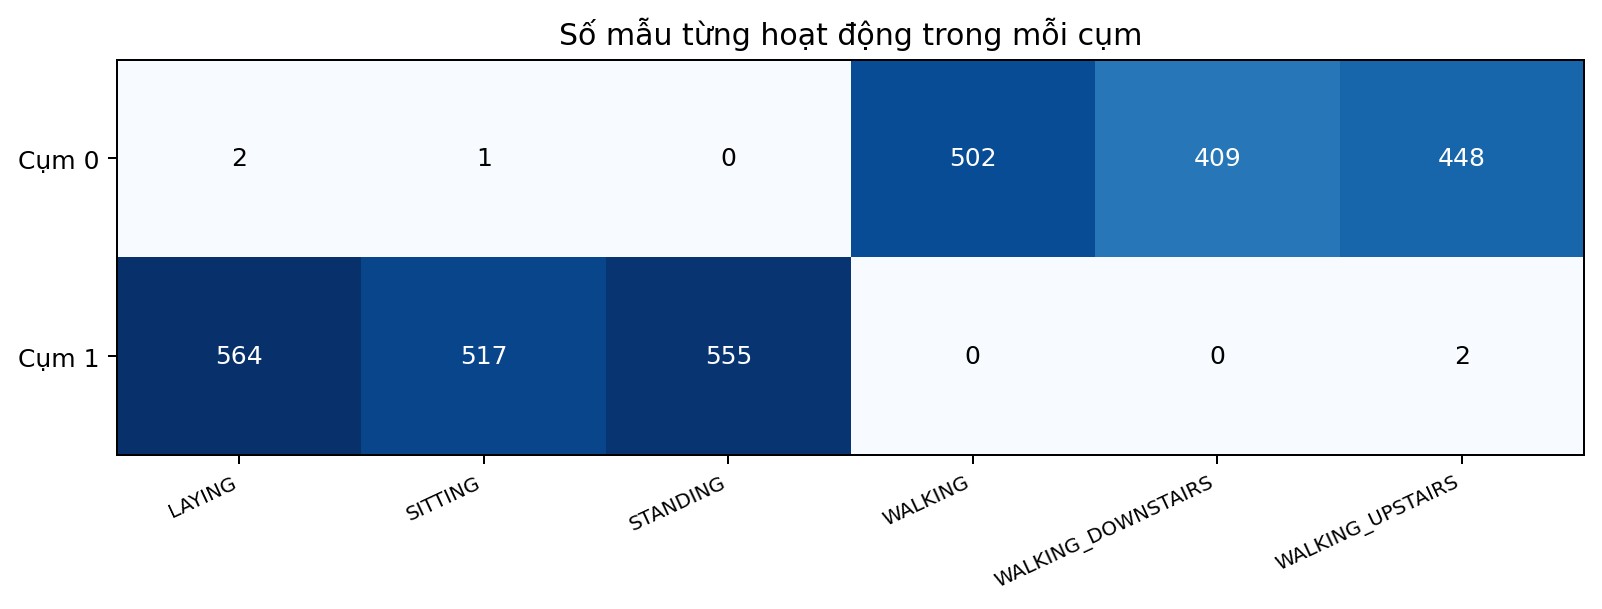

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Fit_seconds,Iterations,Min_cluster_size,Max_cluster_size,ARI,NMI
4,6,653573.611215,0.133631,2.161166,857.717375,0.191484,12,59,791,0.416495,0.562532


,Cluster,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
0,0,449,23,0,0,0,0
1,1,0,0,0,183,251,78
2,2,1,0,0,301,117,372
3,3,101,126,171,0,0,0
4,4,15,369,384,0,0,0
5,5,0,0,0,18,41,0


In [6]:
display(pd.read_csv(OUT / f'activity_crosstab_k{k}.csv'))
display(Image(filename=str(OUT / 'activity_heatmap.png')))
print('Thực nghiệm bổ sung K=6:')
display(results.loc[results['K'] == 6].round(6))
display(pd.read_csv(OUT / 'activity_crosstab_k6.csv'))
print('Tỷ lệ mẫu có Silhouette âm (%):', manifest['negative_silhouette_percent'])


## 7. Bàn giao cho Huy
- `k_sweep.csv`: các chỉ số K=2…10; K cuối được chọn trước khi đối chiếu nhãn.
- `cluster_labels.csv`: giữ nguyên Sample_Index và Original_Index, thêm nhãn cụm cuối.
- `labels_all_k.csv`: nhãn cụm của mọi K để so sánh cùng số cụm nếu cần.
- `cluster_centers.csv`: tâm cụm trong không gian 104 PC.
- `experiment_config.json`: cấu hình, phiên bản thư viện, SHA-256 của đầu vào.
- Các PNG, bảng chéo hoạt động và nội dung báo cáo trong `reports`.

Huy cần dùng cùng file mẫu, thứ tự dòng, PC1…PC104, không chuẩn hóa lại các PC. Nếu khảo sát riêng K=6 hoặc K khác, ghi rõ tiêu chí so sánh. Kết quả K-Means sơ bộ cũ ở `results/kmeans_pca_results.csv` dùng toàn bộ 10.299 mẫu và không dùng để so sánh trực tiếp với tập 3.000 mẫu này.

Lưu ý: nhãn đã được dùng cho lấy mẫu phân tầng ở giai đoạn tiền xử lý; vì vậy đây không phải quy trình hoàn toàn không dùng nhãn ở mọi bước. Tuy nhiên, K-Means và việc chọn K không sử dụng nhãn hoạt động.

## Tài liệu
- [Scikit-learn — K-Means và đánh giá phân cụm](https://scikit-learn.org/stable/modules/clustering.html)
- [Scikit-learn — KMeans API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
